# Cell embeddings and clusters across modalities

This tutorial embeds the same cells by their transcriptome and by their single-cell contact maps, clusters
them, scores the clusters against published cell types (ARI / NMI) and lists marker features.  It then embeds
immunofluorescence (IF) signals that an imaging experiment measured at every DNA spot, and shows how the
embeddings are stored so that the web browser can show them.

- **Modules**: `uchrom.emb` (`embed_cells`, `normalize_counts`, `tfidf_lsi`, `cluster_cells`,
  `marker_features`, `scool_cell_features`, `aggregate_tracks`; `uchrom.emb.hic.schicluster_impute`), `chromdata.ChromData`,
  `uchrom_browser.data`.
- **Data**: the scHiCAR mouse frontal cortex: RNA, ATAC and chromatin contacts measured in the same 5,313 nuclei,
  with 22 published cell types.  Wei et al. 2026, *Nat. Biotechnol.*, GEO GSE305439; we use the store
  `example-data/schicar_mop/` built by `build_schicar_mop.py`.  The second dataset is the Takei et al. 2025
  (*Nature*) cerebellum DNA seqFISH+ with 48 IF channels: replicate 1, 1,799 cells, in
  `example-data/takei2025_cerebellum/`.
- **Getting the data** (both are large and not in the repository; see `example-data/README.md`):
  - scHiCAR: `python example-data/download_data.py --schicar_rna --schicar_dna --schicar_atac`, then
    `python example-data/build_schicar_mop.py`.
  - Takei: `python example-data/download_data.py --takei2025_cerebellum` (2.85 GB), then
    `python example-data/build_takei2025_cerebellum.py`.
- **Runtime**: about 3 min on a laptop CPU.  We use 2,000 of the 5,313 scHiCAR cells, chosen at random, so
  that the contact-map step takes about a minute; with all cells it takes about 4 min.

In [1]:
import os
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.neighbors import NearestNeighbors

from chromdata import ChromData
from uchrom import emb

plt.rcParams["figure.dpi"] = 90
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")   # tqdm, imported by umap-learn


def find_repo_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "example-data" / "README.md").exists():
            return p
    raise FileNotFoundError("run this notebook inside the U-Chrom repository")


REPO = find_repo_root(); DATA = REPO / "example-data"; OUT = REPO / "tutorials" / "_out"; OUT.mkdir(exist_ok=True)
T0 = time.time()

In [2]:
# small helpers used below: agreement scores and scatter plots
def agreement(labels, truth):
    return {"ARI": round(adjusted_rand_score(truth, labels), 3),
            "NMI": round(normalized_mutual_info_score(truth, labels), 3)}


def knn_purity(x, y, k=10):
    # fraction of each cell's k nearest neighbours (Euclidean) that share its label
    y = np.asarray(y)
    idx = NearestNeighbors(n_neighbors=k + 1).fit(x).kneighbors(x, return_distance=False)[:, 1:]
    return round(float((y[idx] == y[:, None]).mean()), 3)


def scatter(ax, xy, labels, title, palette=None, annotate=True, s=4):
    labels = pd.Series(labels).astype(str).to_numpy()
    cats = sorted(set(labels))
    palette = palette or dict(zip(cats, (plt.cm.tab20.colors + plt.cm.Dark2.colors) * 2))
    for c in cats:
        m = labels == c
        ax.scatter(xy[m, 0], xy[m, 1], s=s, lw=0, color=palette[c], label=c)
        if annotate:
            ax.text(*np.median(xy[m], axis=0), c, fontsize=6.5, ha="center", va="center", weight="bold")
    ax.set_title(title, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

## 1. Load the scHiCAR store and pick the cells

The store holds no 3-D coordinates, so it has no spots.  It holds one row per nucleus in `cells`, with the
published `cell_type`, QC numbers, `rna.<gene>` counts and ATAC gene activity `atac.<gene>`.  It also stores
embeddings in `cellm`, and **links** to data kept outside the store:

- a `.scool` file with one contact map per cell at 1 Mb;
- an `.h5ad` file with the full RNA count matrix.

These files are linked, not copied (see the *Linked modalities* guide).

We keep 2,000 random cells and the published UMAP and cell types.  We also keep `atac_lsi`, the ATAC
embedding that the build script computed from 100 kb genome bins of all 5,313 cells.  We use it for
comparison, because the raw ATAC fragments (1.35 GB) are not needed here.  Each cell type also gets a coarse
class: excitatory neurons, inhibitory neurons or non-neuronal cells.

In [3]:
full = ChromData.read(DATA / "schicar_mop" / "schicar_mop.chromdata.zarr")
SCOOL = full.resolve_link_path(full.uns["linked_scool"]["per_cell"]["path"])
print(f"{full.n_cells:,} cells, {full.cells['cell_type'].nunique()} published cell types, "
      f"{sum(c.startswith('rna.') for c in full.cells.columns)} rna.* columns")
print("cellm:", list(full.cellm))
print("linked:", full.uns["linked_scool"]["per_cell"]["path"], "and", full.uns["linked_anndata"]["path"])

N_CELLS = 2000
keep = np.sort(np.random.default_rng(0).choice(full.n_cells, N_CELLS, replace=False))

CLASS = {**dict.fromkeys(["L23IT.1", "L23IT.2", "L23IT.3", "L45IT", "L5IT", "L6IT", "L6CT", "L56NP", "PT", "CLA"],
                         "excitatory"),
         **dict.fromkeys(["Pvalb", "Sst", "Vip", "Lamp5", "D2MSN"], "inhibitory"),
         **dict.fromkeys(["Astro", "Oligo", "OPC", "MGL", "Endo", "Peri", "LMC"], "non-neuronal")}
meta_cols = ["cell_type", "dna_barcode", "n_counts_rna", "n_genes_rna", "n_fragments_atac", "n_contacts_hic"]
cells = full.cells.iloc[keep][meta_cols].copy()
cells["cell_class"] = cells["cell_type"].map(CLASS)

cd = ChromData(np.zeros((0, 3)), full.spots.iloc[:0], cells=cells,
               cellm={k: full.cellm[k][keep] for k in ("paper_umap", "atac_lsi")},
               uns={"genome_assembly": "mm10", "source": full.uns["source"],
                    "embeddings": {k: full.uns["embeddings"][k] for k in ("paper_umap", "atac_lsi")}})
# link the per-cell contact maps (path relative to where the store will be written)
cd.link_scool(os.path.relpath(SCOOL, OUT), key="per_cell", cell_name="cell_id (RNA barcode)",
              genome_assembly="mm10", bin_size=1_000_000)
y_type = cd.cells["cell_type"].astype(str).to_numpy()
y_class = cd.cells["cell_class"].to_numpy()
print(cd.n_cells, "cells kept;", pd.Series(y_class).value_counts().to_dict())

5,313 cells, 22 published cell types, 500 rna.* columns
cellm: ['paper_umap', 'rna_pca', 'rna_tsne', 'rna_umap', 'atac_lsi', 'atac_tsne', 'atac_umap', 'hic_pca', 'hic_tsne', 'hic_umap']
linked: contacts_cells_1Mb.scool and schicar_mop_rna.h5ad
2000 cells kept; {'excitatory': 1305, 'non-neuronal': 448, 'inhibitory': 247}


## 2. RNA: choose variable genes from the linked count matrix

The store's 500 `rna.*` columns were ranked by raw dispersion (variance / mean), which favours genes with low
expression.  Here we read every gene's UMI counts from the linked AnnData (`cd.linked_adata`; its rows follow
`cells`).  We then pick 2,000 highly variable genes with the usual Seurat recipe: log-normalise, then z-score
the dispersion within 20 bins of mean expression.  The genes become `rna.<gene>` columns of `cd.cells`;
`embed_cells` and `marker_features` use them from there.

`normalize_counts` is the normalisation that `embed_cells` applies to count features: library size (optional),
`log1p`, then a z-score per gene.  Here we use it to compare the two gene sets by how well their 30 PCs keep
cells of one type together (k-nearest-neighbour purity, k = 10).

In [4]:
adata = full.linked_adata                                   # lazy: read on first access
assert (adata.obs_names == full.cells.index).all()
X = sp.csr_matrix(adata.X[keep], dtype=np.float64)           # 2,000 cells x every gene
print(f"linked RNA: {adata.n_vars:,} genes; median UMIs per cell {np.median(np.asarray(X.sum(1)).ravel()):,.0f}")


def highly_variable_genes(X, n_top=2000, n_bins=20, min_frac=0.01):
    # Seurat v1-style: dispersion of log-normalised counts, z-scored within bins of mean expression
    totals = np.asarray(X.sum(1)).ravel()
    norm = sp.diags(1e4 / totals) @ X
    norm.data = np.log1p(norm.data)
    mean = np.asarray(norm.mean(0)).ravel()
    var = np.asarray(norm.multiply(norm).mean(0)).ravel() - mean ** 2
    disp = np.log(np.maximum(var, 1e-12) / np.maximum(mean, 1e-12))
    ok = np.asarray((X > 0).mean(0)).ravel() >= min_frac
    frame = pd.DataFrame({"disp": disp, "bin": pd.cut(mean, n_bins)})
    stats = frame[ok].groupby("bin", observed=True)["disp"].agg(["mean", "std"])
    z = (disp - frame["bin"].map(stats["mean"]).astype(float)) / frame["bin"].map(stats["std"]).astype(float)
    z = np.where(ok & np.isfinite(z), z, -np.inf)
    return np.argsort(-z)[:n_top]


hvg = highly_variable_genes(X)
genes = adata.var_names[hvg]
print("first HVGs:", ", ".join(genes[:12]))


def pcs(counts):
    return PCA(30, random_state=0).fit_transform(emb.normalize_counts(counts, library_size=True))


stored_500 = full.cells.iloc[keep][[c for c in full.cells.columns if c.startswith("rna.")]].to_numpy()
hvg_counts = X[:, hvg].toarray()
print("kNN-10 purity of cell types: stored 500 genes", knn_purity(pcs(stored_500), y_type),
      "| 2,000 HVGs", knn_purity(pcs(hvg_counts), y_type))

cd.cells = pd.concat([cd.cells, pd.DataFrame(hvg_counts, index=cd.cells.index,
                                             columns=[f"rna.{g}" for g in genes])], axis=1)

linked RNA: 28,783 genes; median UMIs per cell 17,918


first HVGs: Plp1, Mertk, Slc1a3, Zfp536, Atp1a2, Sox2ot, Daam2, Ptprz1, Dock10, Htra1, Flt1, Adarb2


kNN-10 purity of cell types: stored 500 genes 0.411 | 2,000 HVGs 0.859


## 3. `embed_cells`: PCA, t-SNE and UMAP

`embed_cells(cd, source="rna")` selects the numeric `rna.*` columns.  Count features are normalised with
`normalize_counts`; `library_size=True` suits transcriptome-wide data.  The function then runs PCA on the
normalised matrix, and t-SNE and UMAP on the PCs.  The results are `cd.cellm["rna_pca"]`, `["rna_tsne"]` and
`["rna_umap"]`, with rows in the order of `cd.cells`.  The parameters go to `cd.uns["embeddings"]`.

{'rna_pca': (2000, 30), 'rna_tsne': (2000, 2), 'rna_umap': (2000, 2)} in 35 s
library-size (median total), log1p, z-score per feature | 2000 features | variance of PC1-5: [0.05  0.029 0.026 0.021 0.018]


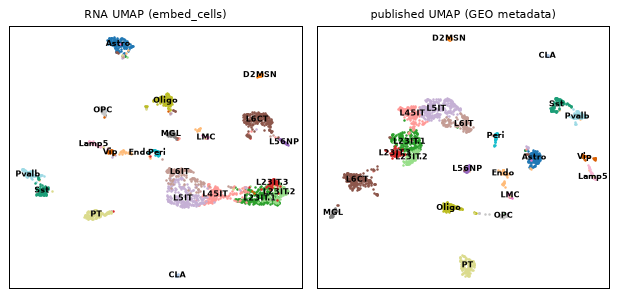

In [5]:
t = time.time()
out = emb.embed_cells(cd, source="rna", library_size=True, n_pcs=30)
print({k: v.shape for k, v in out.items()}, f"in {time.time() - t:.0f} s")
meta = cd.uns["embeddings"]["rna_pca"]
print(meta["normalization"], "|", meta["n_features"], "features | variance of PC1-5:",
      np.round(meta["explained_variance_ratio"][:5], 3))

fig, axes = plt.subplots(1, 2, figsize=(7, 3.4))
scatter(axes[0], cd.cellm["rna_umap"], y_type, "RNA UMAP (embed_cells)")
scatter(axes[1], cd.cellm["paper_umap"], y_type, "published UMAP (GEO metadata)")
fig.tight_layout()

## 4. `cluster_cells`: Leiden clusters and agreement with the published cell types

`cluster_cells` builds a k-nearest-neighbour graph (k = 15) on an embedding and partitions it with the Leiden
algorithm.  The labels are stored as a categorical column of `cd.cells` and the parameters in
`cd.uns["clusters"]`.  We compare them with the 22 published cell types and with the three coarse classes,
using the adjusted Rand index (ARI; 0 = chance, 1 = identical) and normalised mutual information (NMI).

In [6]:
lab_rna = emb.cluster_cells(cd, use="rna_pca", resolution=1.0, key_added="leiden_rna")
print(f"{lab_rna.nunique()} RNA clusters;", "vs cell types", agreement(lab_rna, y_type),
      "| vs coarse classes", agreement(lab_rna, y_class))

# each cluster: size, its most frequent published type and that type's share
tab = pd.crosstab(lab_rna, cd.cells["cell_type"])
summary = pd.DataFrame({"n_cells": tab.sum(axis=1), "main_type": tab.idxmax(axis=1),
                        "share": (tab.max(axis=1) / tab.sum(axis=1)).round(2)})
summary.T

17 RNA clusters; vs cell types {'ARI': 0.675, 'NMI': 0.804} | vs coarse classes {'ARI': 0.144, 'NMI': 0.414}


leiden_rna,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
n_cells,256,222,205,173,163,160,116,115,108,95,79,74,60,54,49,37,34
main_type,L23IT.1,L6IT,L6CT,L5IT,L23IT.2,Astro,Oligo,PT,L45IT,Lamp5,Pvalb,Sst,D2MSN,MGL,OPC,Peri,L56NP
share,0.71,0.57,0.99,0.92,0.43,0.91,0.92,0.98,0.94,0.43,0.92,0.99,0.4,0.83,0.92,0.89,0.94


Most clusters map to one published type: more than 80 % of their cells share it.  The exceptions are
the L2/3 IT subgroups, L6 IT and two small interneuron groups (Lamp5, D2MSN), which the clusters of 2,000 cells
at resolution 1 mix with their neighbours.  The published labels come from a finer analysis of the full
transcriptome of all cells.  So the ARI is well below 1, while the NMI stays high.

## 5. `marker_features`: what distinguishes each group

`marker_features` ranks the `prefix` columns of `cd.cells` by the difference of the mean of `log1p(value)`
between a group and all other cells.  Applied to the published types, it recovers known markers:

- *Plp1* / *Mobp* / *St18* in oligodendrocytes and *Ptprz1* in OPCs;
- *Slc1a2* / *Slc1a3* in astrocytes and *Inpp5d* / *Dock2* in microglia;
- *Kcnc2* in Pvalb interneurons;
- *Foxp2* in L6 corticothalamic neurons and *Tshz2* in L5/6 near-projecting neurons.

Applied to the Leiden clusters, it describes clusters that have no label yet; for example, *Cux2* comes out
for the L2/3 IT cluster.

In [7]:
by_type = emb.marker_features(cd, "cell_type", prefix="rna.", n_top=4)
show = ["Oligo", "OPC", "Astro", "MGL", "Endo", "Peri", "Pvalb", "Sst", "Vip", "L6CT", "PT", "L56NP"]
display(pd.DataFrame({t: by_type[t] for t in show}).rename_axis("rank"))

by_cluster = emb.marker_features(cd, "leiden_rna", prefix="rna.", n_top=4)
pd.DataFrame({f"{c} ({summary.loc[c, 'main_type']})": by_cluster[c] for c in summary.index[:8]}).rename_axis("rank")

,Oligo,OPC,Astro,MGL,Endo,Peri,Pvalb,Sst,Vip,L6CT,PT,L56NP
rank,,,,,,,,,,,,
0,Plp1,Lhfpl3,Gpc5,Tgfbr1,Bnc2,Flt1,Erbb4,Nxph1,Adarb2,Hs3st4,Tafa1,Tshz2
1,St18,Sox2ot,Slc1a2,Inpp5d,Fbxl7,Slco1a4,Nxph1,Grik1,Erbb4,Foxp2,Gm2164,Vwc2l
2,Mobp,Nxph1,Slc1a3,Lrmda,Eya2,Ebf1,Kcnc2,Synpr,Npas3,Zfpm2,Pex5l,Nxph1
3,Mbp,Ptprz1,Mertk,Dock2,Nxn,Mecom,Btbd11,Npas3,Zfp536,Grik3,Tcerg1l,Olfm3


,0 (L23IT.1),1 (L6IT),2 (L6CT),3 (L5IT),4 (L23IT.2),5 (Astro),6 (Oligo),7 (PT)
rank,,,,,,,,
0,Cux2,Galnt14,Hs3st4,Pcdh15,Epha6,Gpc5,Plp1,Tafa1
1,Lingo2,Sorcs3,Foxp2,Cpne4,Slit3,Slc1a2,St18,Gm2164
2,Rasgrf2,Il1rapl2,Zfpm2,Cntn5,March1,Mertk,Mbp,Pex5l
3,Unc5d,Grik3,Grik3,Zfp804b,Grm1,Slc1a3,Mobp,Tcerg1l


## 6. Contact maps: scHiCluster features from the linked `.scool`

The same nuclei also have a contact map.  `scool_cell_features` computes the features of scHiCluster (Zhou
et al. 2019, *PNAS*) as follows:

1. Read the 1 Mb intra-chromosomal map of each chromosome of each cell from the `.scool`.
2. Smooth it with a 3 × 3 convolution.
3. Impute it by random walk with restart (`uchrom.emb.hic.schicluster_impute`).
4. Keep the top 20 % of the entries (set them to 1, the rest to 0).
5. Reduce each chromosome to 20 PCs across cells, and concatenate the PCs of all chromosomes.

First, look at one cell: the raw map is very sparse, and imputation spreads its contacts along the diagonal
and into domains.

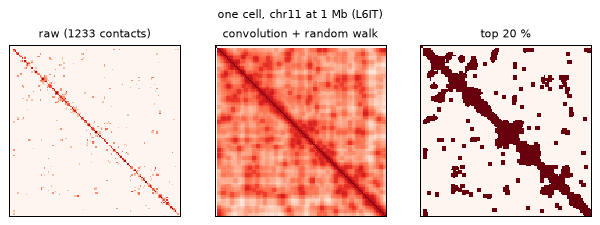

In [8]:
import cooler
from uchrom.emb.hic import schicluster_impute

cell = cd.cells["n_contacts_hic"].sort_values().index[int(0.75 * cd.n_cells)]   # a cell at the 75th depth percentile
raw = cooler.Cooler(f"{SCOOL}::/cells/{cell}").matrix(balance=False).fetch("chr11").astype(float)
imputed = schicluster_impute(raw, pad=1, rp=0.5)
iu = np.triu_indices_from(imputed, 1)
binary = imputed > np.percentile(imputed[iu], 80)

fig, axes = plt.subplots(1, 3, figsize=(7, 2.5))
for ax, m, title in zip(axes, [np.log1p(raw), np.log(np.maximum(imputed, 1e-6)), binary],
                        [f"raw ({int(np.triu(raw).sum())} contacts)", "convolution + random walk", "top 20 %"]):
    ax.imshow(m, cmap="Reds", interpolation="none")
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"one cell, chr11 at 1 Mb ({cd.cells.loc[cell, 'cell_type']})", fontsize=9)
fig.tight_layout()

Now compute the features of all 2,000 cells (about a minute) and embed them.  The features are already
reduced and scaled, so `embed_cells` gets them as a `matrix=` with `normalization="none"`.  The `features=` text
is recorded with the embedding.

In [9]:
CHROMS = [f"chr{i}" for i in range(1, 20)] + ["chrX"]
t = time.time()
feats, cols, depth = emb.scool_cell_features(str(SCOOL), [str(c) for c in cd.cells.index], chroms=CHROMS)
print(f"scHiCluster features {feats.shape} in {time.time() - t:.0f} s; e.g. {cols[:3]}")
assert (depth == cd.cells["n_contacts_hic"].to_numpy()).all()    # contacts read = the stored per-cell totals

emb.embed_cells(cd, source="hic", matrix=feats, normalization="none", n_pcs=20,
                features="scHiCluster: 1 Mb maps chr1-19, X; 3x3 convolution, random walk (rp=0.5), "
                         "top 20% binarised, 20 PCs per chromosome")
r_depth = [round(float(np.corrcoef(cd.cellm["hic_pca"][:, j], np.log(depth))[0, 1]), 2) for j in range(3)]
print("Pearson r of Hi-C PC1-3 with log(contacts):", r_depth)

lab_hic = emb.cluster_cells(cd, use="hic_pca", resolution=1.0, key_added="leiden_hic")
lab_hic2 = emb.cluster_cells(cd, use="hic_pca", resolution=0.3, key_added="leiden_hic_coarse")
print(f"{lab_hic.nunique()} Hi-C clusters (resolution 1):", "vs cell types", agreement(lab_hic, y_type))
print(f"{lab_hic2.nunique()} Hi-C clusters (resolution 0.3):", "vs coarse classes", agreement(lab_hic2, y_class))
pd.crosstab(lab_hic2, cd.cells["cell_class"]).rename_axis(index="leiden_hic_coarse", columns=None)

scHiCluster features (2000, 400) in 127 s; e.g. ['chr1_PC1', 'chr1_PC2', 'chr1_PC3']


Pearson r of Hi-C PC1-3 with log(contacts): [-0.23, 0.57, -0.04]


6 Hi-C clusters (resolution 1): vs cell types {'ARI': 0.11, 'NMI': 0.243}
2 Hi-C clusters (resolution 0.3): vs coarse classes {'ARI': 0.573, 'NMI': 0.53}


,excitatory,inhibitory,non-neuronal
leiden_hic_coarse,,,
0,1272,233,35
1,33,14,413


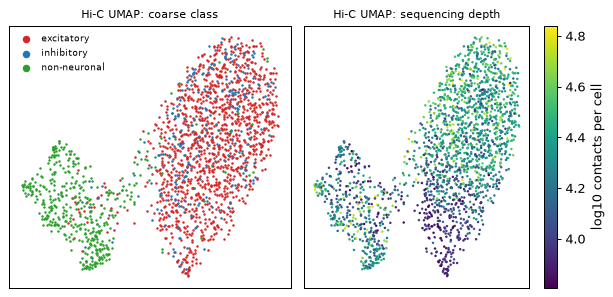

In [10]:
CLASS_COLORS = {"excitatory": "tab:red", "inhibitory": "tab:blue", "non-neuronal": "tab:green"}
fig, axes = plt.subplots(1, 2, figsize=(7, 3.4))
scatter(axes[0], cd.cellm["hic_umap"], y_class, "Hi-C UMAP: coarse class", palette=CLASS_COLORS, annotate=False)
axes[0].legend(fontsize=7, markerscale=3, frameon=False, loc="best")
xy = cd.cellm["hic_umap"]
sc = axes[1].scatter(xy[:, 0], xy[:, 1], s=4, lw=0, c=np.log10(cd.cells["n_contacts_hic"]), cmap="viridis")
fig.colorbar(sc, ax=axes[1], label="log10 contacts per cell")
axes[1].set_title("Hi-C UMAP: sequencing depth", fontsize=9); axes[1].set_xticks([]); axes[1].set_yticks([])
fig.tight_layout()

At 1 Mb, single-cell contact maps separate neurons from non-neuronal cells, but not the finer neuronal
subtypes.  The fine-type ARI is therefore much lower than for RNA.  Within the neurons, the main gradient
follows the number of contacts per cell: PC2 tracks sequencing depth (r above).

## 7. Sparse counts: `tfidf_lsi` and the agreement of the modalities

For sparse counts such as ATAC fragments, `embed_cells(..., normalization="tfidf")` (the default for
`source="atac"`) calls `tfidf_lsi`: TF-IDF, then truncated SVD (latent semantic indexing).  Component 1 is
dropped when it tracks sequencing depth.  The store's `atac.*` columns count fragments in the gene body + 2 kb
of 484 genes, and they show the depth effect clearly.  These windows hold few fragments per cell, so the
build script used 100 kb genome bins for the stored `atac_lsi` instead.

In [11]:
gact = full.cells.iloc[keep][[c for c in full.cells.columns if c.startswith("atac.")]].to_numpy()
lsi, info = emb.tfidf_lsi(gact, n_components=30)
print(f"gene-activity counts: median {np.median(gact.sum(1)):.0f} fragments per cell in {gact.shape[1]} genes")
print("r(LSI component, log depth) for components 1-3:", np.round(info["depth_r"][:3], 2),
      "-> dropped", info["dropped"])
print("kNN-10 purity: gene-activity LSI", knn_purity(lsi, y_type),
      "| stored atac_lsi (100 kb bins)", knn_purity(cd.cellm["atac_lsi"], y_type))

gene-activity counts: median 630 fragments per cell in 484 genes
r(LSI component, log depth) for components 1-3: [ 0.98 -0.76 -0.13] -> dropped [1]
kNN-10 purity: gene-activity LSI 0.104 | stored atac_lsi (100 kb bins) 0.298


The same cells, four views.  Leiden clusters are computed at resolution 1 on each linear embedding and
compared with the 22 types.  The kNN purity is measured in the embedding itself, for the 22 types and for the
3 classes.  Its chance level is the purity after shuffling the labels; it is printed first.

In [12]:
lab_atac = emb.cluster_cells(cd, use="atac_lsi", resolution=1.0, key_added="leiden_atac")
rows = []
for key, lab in [("rna_pca", lab_rna), ("atac_lsi", lab_atac), ("hic_pca", lab_hic), ("paper_umap", None)]:
    x = cd.cellm[key]
    row = {"embedding": key, "modality": cd.uns["embeddings"][key]["modality"], "dims": x.shape[1],
           "kNN purity (type)": knn_purity(x, y_type), "kNN purity (class)": knn_purity(x, y_class)}
    if lab is not None:
        row.update({"clusters": lab.nunique(), "ARI type": agreement(lab, y_type)["ARI"],
                    "NMI type": agreement(lab, y_type)["NMI"]})
    rows.append(row)
rng = np.random.default_rng(1)
print("chance purity:", knn_purity(cd.cellm["rna_pca"], rng.permutation(y_type)),
      "(type),", knn_purity(cd.cellm["rna_pca"], rng.permutation(y_class)), "(class)")
print("ARI between RNA and Hi-C clusters:", round(adjusted_rand_score(lab_rna, lab_hic), 3),
      "| RNA and ATAC clusters:", round(adjusted_rand_score(lab_rna, lab_atac), 3))
pd.DataFrame(rows).set_index("embedding")

chance purity: 0.07 (type), 0.489 (class)
ARI between RNA and Hi-C clusters: 0.118 | RNA and ATAC clusters: 0.251


,modality,dims,kNN purity (type),kNN purity (class),clusters,ARI type,NMI type
embedding,,,,,,,
rna_pca,RNA,30,0.859,0.972,17.0,0.675,0.804
atac_lsi,ATAC,30,0.298,0.826,7.0,0.226,0.382
hic_pca,Hi-C,20,0.235,0.761,6.0,0.110,0.243
paper_umap,Published,2,0.934,0.979,NaN,NaN,NaN


## 8. Imaging: IF signals summarised per cell (`aggregate_tracks`)

DNA seqFISH+ in the Takei 2025 cerebellum measured 48 IF channels at every DNA spot (histone marks, nuclear
bodies, chromatin proteins); they are stored as `spot_tracks`.  `aggregate_tracks` turns per-spot tracks into
per-cell features:

- `stat="mean"` gives one mean per channel (`if.<mark>`), useful for colouring;
- `stat="corr"` gives the within-cell Pearson correlation of every pair of channels over the cell's spots
  (1,128 pairs).  This describes which marks occur together on the same loci and does not depend on each cell's
  overall staining intensity.

The store has 10.9 M spots, so we open it backed and stream it with `iter_cells`, reading only the 48 IF tracks.

In [13]:
from uchrom.io.seqfish_multiomics import IF_COLUMNS

t = time.time()
takei = ChromData.read(DATA / "takei2025_cerebellum" / "takei2025_cerebellum_rep1.chromdata.zarr", backed=True)
marks = [c for c in IF_COLUMNS if c in takei.spot_tracks.columns]
print(f"{takei.n_cells:,} cells, {takei.n_spots:,} spots, {len(marks)} IF channels, e.g. {marks[:6]}")

corr, means = [], []
for chunk in takei.iter_cells(batch=64, columns="coords", tracks=marks):
    corr.append(emb.aggregate_tracks(chunk, marks, prefix="if", stat="corr", write=False))
    means.append(emb.aggregate_tracks(chunk, marks, prefix="if", stat="mean", write=False))
order = takei.cells.index.astype(str)
corr = pd.concat(corr).reindex(order)
means = pd.concat(means).reindex(order).set_axis(takei.cells.index)
takei.cells = pd.concat([takei.cells, means], axis=1)        # if.<mark> means as cell columns
print(f"per-cell features: corr {corr.shape}, means {means.shape} in {time.time() - t:.0f} s")

emb.embed_cells(takei, source="if", matrix=corr.to_numpy(), normalization="zscore", n_pcs=20,
                features="within-cell Pearson r of 48 IF channels over all spots (1,128 pairs)")
y_cb = takei.cells["cell_type"].astype(str).to_numpy()
lab_if = emb.cluster_cells(takei, use="if_pca", resolution=0.3, key_added="leiden_if")
print(f"{lab_if.nunique()} IF clusters:", agreement(lab_if, y_cb),
      "| kNN-10 purity", knn_purity(takei.cellm["if_pca"], y_cb),
      "(chance", knn_purity(takei.cellm["if_pca"], np.random.default_rng(1).permutation(y_cb)), ")")
z_means = ((means - means.mean()) / means.std()).to_numpy()   # the means are z-scores already; rescale per mark
print("with per-cell means instead of correlations: kNN-10 purity",
      knn_purity(PCA(20, random_state=0).fit_transform(z_means), y_cb))
pd.crosstab(lab_if, takei.cells["cell_type"]).rename_axis(index="leiden_if", columns=None)

1,799 cells, 10,912,638 spots, 48 IF channels, e.g. ['CPSF6', 'ATRX', 'H4K8ac', 'HDAC2', 'H3K9ac', 'H3K9me3']


per-cell features: corr (1799, 1128), means (1799, 48) in 9 s


4 IF clusters: {'ARI': 0.299, 'NMI': 0.386} | kNN-10 purity 0.737 (chance 0.426 )
with per-cell means instead of correlations: kNN-10 purity 0.667


,Bergmann,Granule,MLI1,MLI2+PLI,Other,Purkinje
leiden_if,,,,,,
0,9,650,0,3,161,3
1,21,452,5,0,107,2
2,160,6,4,1,46,3
3,2,1,81,23,9,50


,Granule,Bergmann,Other,MLI1,Purkinje,MLI2+PLI
rank,,,,,,
0,RING1B,H3K9ac,LaminB1,mH2A1,H3K27me3,mH2A1
1,H3,SOX2,SUZ12,H3K9ac,H4K8ac,H3K9me3
2,SUZ12,H3K27ac,SF3A66,H3K27ac,H3K9ac,H3K9ac


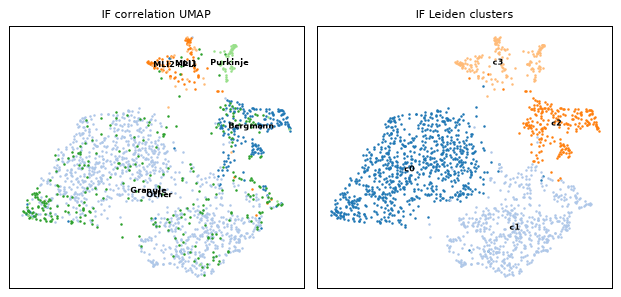

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3.4))
scatter(axes[0], takei.cellm["if_umap"], y_cb, "IF correlation UMAP")
scatter(axes[1], takei.cellm["if_umap"], lab_if.astype(str).radd("c"), "IF Leiden clusters", annotate=True)
fig.tight_layout()

top = emb.marker_features(takei, "cell_type", prefix="if.", n_top=3, log=False)   # IF values are z-scores
pd.DataFrame(top).rename_axis("rank")

The IF correlation embedding groups the cerebellar types well above chance, and better than the per-cell
means.  The Leiden clusters give:

- one cluster of Bergmann glia;
- one cluster of the molecular-layer interneurons (MLI1, MLI2+PLI) together with the Purkinje cells;
- two clusters that both mix granule cells with the heterogeneous "Other" group.

So the ARI stays modest.  The published types were derived from the transcriptome, so they are a demanding
reference for chromatin marks alone.  Among the per-cell means, SOX2 comes out for Bergmann glia, which express
it.

## 9. How embeddings are stored

- `cd.cellm[key]`: one array per embedding, with rows aligned with `cd.cells` (`rna_pca`, `rna_umap`,
  `hic_pca`, ...).
- `cd.uns["embeddings"][key]`: what `embed_cells` recorded.  This includes `source`, `modality`, `method`,
  `label` and `axis_prefix`, plus the normalisation, the number of features and their names, and the
  explained variance.  The web browser groups its *Embedding* view by `modality` and labels the axes with
  `axis_prefix`.
- `cd.uns["clusters"][key]`: the Leiden parameters.  The labels themselves are categorical `cd.cells` columns,
  which the browser offers as colourings, like `cell_type`.

All of this round-trips through a `.chromdata.zarr` store.  The `.scool` stays linked: its relative path
resolves against the folder of the store.

In [15]:
pd.DataFrame(cd.uns["embeddings"]).T[["source", "modality", "method", "label", "axis_prefix", "n_features"]]

,source,modality,method,label,axis_prefix,n_features
paper_umap,GSE305439 metadata,Published,umap,Paper UMAP (RNA),UMAP,NaN
atac_lsi,atac,ATAC,lsi,ATAC LSI,LSI,25461
rna_pca,rna,RNA,pca,RNA PCA,PC,2000
rna_tsne,rna,RNA,tsne,RNA t-SNE,tSNE,2000
rna_umap,rna,RNA,umap,RNA UMAP,UMAP,2000
hic_pca,hic,Hi-C,pca,Hi-C PCA,PC,400
hic_tsne,hic,Hi-C,tsne,Hi-C t-SNE,tSNE,400
hic_umap,hic,Hi-C,umap,Hi-C UMAP,UMAP,400


In [16]:
path = OUT / "schicar_mop_2000_embeddings.chromdata.zarr"
cd.write(path)
back = ChromData.read(path)
same = all(np.allclose(back.cellm[k], cd.cellm[k]) for k in cd.cellm)
print(path.relative_to(REPO), "| cellm keys:", sorted(back.cellm), "| arrays equal:", same)
print("clusters:", {k: v["n_clusters"] for k, v in back.uns["clusters"].items()},
      "| link problems:", back.validate_links())

# what the web browser lists for this store (the same call its /api/datasets endpoint makes)
from uchrom_browser.data import DatasetStore

ds = DatasetStore().load(str(path))
pd.DataFrame(ds.embeddings())

tutorials/_out/schicar_mop_2000_embeddings.chromdata.zarr | cellm keys: ['atac_lsi', 'hic_pca', 'hic_tsne', 'hic_umap', 'paper_umap', 'rna_pca', 'rna_tsne', 'rna_umap'] | arrays equal: True


clusters: {'leiden_rna': 17, 'leiden_hic': 6, 'leiden_hic_coarse': 2, 'leiden_atac': 7} | link problems: []


,key,method,source,modality,label,n_dims
0,paper_umap,umap,GSE305439 metadata,Published,Paper UMAP (RNA),2
1,atac_lsi,lsi,atac,ATAC,ATAC LSI,30
2,rna_pca,pca,rna,RNA,RNA PCA,30
3,rna_tsne,tsne,rna,RNA,RNA t-SNE,2
4,rna_umap,umap,rna,RNA,RNA UMAP,2
5,hic_pca,pca,hic,Hi-C,Hi-C PCA,20
6,hic_tsne,tsne,hic,Hi-C,Hi-C t-SNE,2
7,hic_umap,umap,hic,Hi-C,Hi-C UMAP,2


To look at the store interactively, run `python -m uchrom_browser tutorials/_out/schicar_mop_2000_embeddings.chromdata.zarr`.
The *Embedding* view lists the arrays above, grouped by modality, and can colour cells by `cell_type`, the
Leiden columns or any `rna.<gene>`.  The linked `.scool` shows the contact map of a selected cell.

In [17]:
print(f"total runtime {time.time() - T0:.0f} s")

total runtime 192 s


## Next steps

- `higashi_embedding.ipynb`: a contact-map embedding with FastHigashi (tensor decomposition) instead of
  scHiCluster, on sci-Hi-C of two cell lines.
- `plotting_and_browser.ipynb`: the web browser (`uchrom_browser`), which shows the embeddings stored here.
- `chromdata_basics.ipynb` and `chromdata_stores.ipynb`: the `ChromData` container (`cells`, `cellm`, `uns`,
  linked files) and its `.chromdata.zarr` store, including backed reading as used for the Takei data.
- `import_seqfish_multiomics.ipynb`: the Takei 2025 seqFISH+ data: traces, IF tracks and cell types.